In [10]:
# Import the libraries for working with tables, images, and plots.
# Locate the JPEG dataset and annotation files, and set a seed so random choices can be repeated.

from pathlib import Path
import hashlib
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageOps
from IPython.display import display
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")

SEED = 4914
random.seed(SEED)
np.random.seed(SEED)

here = Path.cwd().resolve()
ml_root = next(
    (
        folder
        for parent in (here, *here.parents)
        for folder in (parent, parent / "ml-models")
        if (folder / "data/manifests/sharepoint_gemini/annotations.jsonl").is_file()
    ),
    None,
)

if ml_root is None:
    raise FileNotFoundError("Could not locate the ml-models directory.")

raw_dir = ml_root / "data/raw/sharepoint_data"
jpg_dir = ml_root / "data/transformed/sharepoint_jpg"

original_manifest = (
    ml_root / "data/manifests/sharepoint_gemini/annotations.jsonl"
)
jpg_manifest = (
    ml_root / "data/manifests/sharepoint_jpg/annotations.jsonl"
)

print(f"JPEG dataset: {jpg_dir}")

JPEG dataset: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/data/transformed/sharepoint_jpg


In [11]:
# Create a separate annotation file that points to the converted JPEG images.
# Keep the original labels and source references, check that each JPEG exists, and calculate its file hash.
# Save the JPEG manifest without changing the original annotation file.

with original_manifest.open(encoding="utf-8") as file:
    original_records = [
        json.loads(line) for line in file if line.strip()
    ]

# Keep the latest annotation for each original image
latest_records = {}
for record in sorted(
    original_records,
    key=lambda record: record.get("completed_at", ""),
):
    latest_records[record["raw_path"]] = record

jpg_records = []

for record in tqdm(
    latest_records.values(),
    total=len(latest_records),
    desc="Building JPEG manifest",
):
    original_path = ml_root / record["raw_path"]
    relative_path = original_path.relative_to(raw_dir)
    jpg_path = jpg_dir / relative_path.with_suffix(".jpg")

    if not jpg_path.is_file():
        raise FileNotFoundError(f"Missing converted image: {jpg_path}")

    # Hash the JPEG itself, rather than retaining the HEIC hash
    with jpg_path.open("rb") as file:
        jpg_hash = hashlib.file_digest(file, "sha256").hexdigest()

    jpg_record = {
        **record,
        "source_raw_path": record["raw_path"],
        "source_sha256": record.get("sha256"),
        "raw_path": jpg_path.relative_to(ml_root).as_posix(),
        "sha256": jpg_hash,
    }

    jpg_records.append(jpg_record)

# Write only after every referenced JPEG has been found
jpg_manifest.parent.mkdir(parents=True, exist_ok=True)
temporary_manifest = jpg_manifest.with_suffix(".jsonl.tmp")

with temporary_manifest.open("w", encoding="utf-8") as file:
    for record in jpg_records:
        file.write(json.dumps(record, ensure_ascii=False) + "\n")

temporary_manifest.replace(jpg_manifest)

print(f"Manifest records: {len(jpg_records):,}")
print(f"Saved to: {jpg_manifest}")

Building JPEG manifest:   0%|          | 0/1408 [00:00<?, ?it/s]

Manifest records: 1,408
Saved to: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/data/manifests/sharepoint_jpg/annotations.jsonl


In [13]:
# Load the JPEG annotations into a table of image paths, mango varieties, and interior or exterior views.
# Clean up capitalization and spacing in variety names, remove unlabeled images, and assign each variety a numeric class ID.
# Display the dataset counts and a few example rows.

with jpg_manifest.open(encoding="utf-8") as file:
    records = [json.loads(line) for line in file if line.strip()]

annotations = pd.json_normalize(records)

annotations = (
    annotations.sort_values("completed_at", kind="stable")
    .drop_duplicates("raw_path", keep="last")
)

df = pd.DataFrame({
    "image_path": annotations["raw_path"].map(
        lambda path: str(ml_root / path)
    ),
    "class_name": (
        annotations["annotation.cultivar"]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    ),
    "view": (
        annotations["annotation.view_type"]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace("", pd.NA)
        .fillna("unknown")
    ),
})

unlabeled_count = df["class_name"].isna().sum()
df = df.dropna(subset=["class_name"]).reset_index(drop=True)

class_names = sorted(df["class_name"].unique())
class_to_id = {
    name: index for index, name in enumerate(class_names)
}
label_map = {
    index: name for name, index in class_to_id.items()
}

df["class_id"] = df["class_name"].map(class_to_id)
df = df[["image_path", "class_id", "class_name", "view"]]

print(f"Labeled images: {len(df):,}")
print(f"Unique classes: {len(class_names)}")
print(f"Images without labels: {unlabeled_count:,}")

display(df.head())

Labeled images: 1,387
Unique classes: 222
Images without labels: 21


,image_path,class_id,class_name,view
0,/Users/danielgeorge/Desktop/coding/cis4914-sen...,208,UGLY BETTY,exterior
1,/Users/danielgeorge/Desktop/coding/cis4914-sen...,50,EDWARD,exterior
2,/Users/danielgeorge/Desktop/coding/cis4914-sen...,50,EDWARD,exterior
3,/Users/danielgeorge/Desktop/coding/cis4914-sen...,31,CARABAO,exterior
4,/Users/danielgeorge/Desktop/coding/cis4914-sen...,31,CARABAO,exterior


In [14]:
# Count the labeled images and unique mango varieties for interior, exterior, and unknown views.
# Show combined totals, counting each variety only once even when it appears in multiple views.

summary_rows = []

for name, subset in [
    ("Interior", df[df["view"].eq("interior")]),
    ("Exterior", df[df["view"].eq("exterior")]),
    (
        "Unknown / other",
        df[~df["view"].isin(["interior", "exterior"])],
    ),
    ("Combined (all views)", df),
]:
    summary_rows.append({
        "View": name,
        "Unique classes": subset["class_name"].nunique(),
        "Labeled images": len(subset),
    })

display(pd.DataFrame(summary_rows).set_index("View"))

,Unique classes,Labeled images
View,,
Interior,210,635
Exterior,216,751
Unknown / other,1,1
Combined (all views),222,1387


In [15]:
# Import the libraries for working with tables, images, and plots.
# Locate the JPEG dataset and annotation files, and set a seed so random choices can be repeated.

from pathlib import Path
import hashlib
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageOps
from IPython.display import display
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")

SEED = 4914
random.seed(SEED)
np.random.seed(SEED)

here = Path.cwd().resolve()
ml_root = next(
    (
        folder
        for parent in (here, *here.parents)
        for folder in (parent, parent / "ml-models")
        if (folder / "data/manifests/sharepoint_gemini/annotations.jsonl").is_file()
    ),
    None,
)

if ml_root is None:
    raise FileNotFoundError("Could not locate the ml-models directory.")

raw_dir = ml_root / "data/raw/sharepoint_data"
jpg_dir = ml_root / "data/transformed/sharepoint_jpg"

original_manifest = (
    ml_root / "data/manifests/sharepoint_gemini/annotations.jsonl"
)
jpg_manifest = (
    ml_root / "data/manifests/sharepoint_jpg/annotations.jsonl"
)

print(f"JPEG dataset: {jpg_dir}")

JPEG dataset: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/data/transformed/sharepoint_jpg


In [16]:
# Create a separate annotation file that points to the converted JPEG images.
# Keep the original labels and source references, check that each JPEG exists, and calculate its file hash.
# Save the JPEG manifest without changing the original annotation file.

with original_manifest.open(encoding="utf-8") as file:
    original_records = [
        json.loads(line) for line in file if line.strip()
    ]

# Keep the latest annotation for each original image
latest_records = {}
for record in sorted(
    original_records,
    key=lambda record: record.get("completed_at", ""),
):
    latest_records[record["raw_path"]] = record

jpg_records = []

for record in tqdm(
    latest_records.values(),
    total=len(latest_records),
    desc="Building JPEG manifest",
):
    original_path = ml_root / record["raw_path"]
    relative_path = original_path.relative_to(raw_dir)
    jpg_path = jpg_dir / relative_path.with_suffix(".jpg")

    if not jpg_path.is_file():
        raise FileNotFoundError(f"Missing converted image: {jpg_path}")

    # Hash the JPEG itself, rather than retaining the HEIC hash
    with jpg_path.open("rb") as file:
        jpg_hash = hashlib.file_digest(file, "sha256").hexdigest()

    jpg_record = {
        **record,
        "source_raw_path": record["raw_path"],
        "source_sha256": record.get("sha256"),
        "raw_path": jpg_path.relative_to(ml_root).as_posix(),
        "sha256": jpg_hash,
    }

    jpg_records.append(jpg_record)

# Write only after every referenced JPEG has been found
jpg_manifest.parent.mkdir(parents=True, exist_ok=True)
temporary_manifest = jpg_manifest.with_suffix(".jsonl.tmp")

with temporary_manifest.open("w", encoding="utf-8") as file:
    for record in jpg_records:
        file.write(json.dumps(record, ensure_ascii=False) + "\n")

temporary_manifest.replace(jpg_manifest)

print(f"Manifest records: {len(jpg_records):,}")
print(f"Saved to: {jpg_manifest}")

Building JPEG manifest:   0%|          | 0/1408 [00:00<?, ?it/s]

Manifest records: 1,408
Saved to: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/data/manifests/sharepoint_jpg/annotations.jsonl


In [17]:
# Load the JPEG annotations into a table of image paths, mango varieties, and interior or exterior views.
# Clean up capitalization and spacing in variety names, remove unlabeled images, and assign each variety a numeric class ID.
# Display the dataset counts and a few example rows.

with jpg_manifest.open(encoding="utf-8") as file:
    records = [json.loads(line) for line in file if line.strip()]

annotations = pd.json_normalize(records)

annotations = (
    annotations.sort_values("completed_at", kind="stable")
    .drop_duplicates("raw_path", keep="last")
)

df = pd.DataFrame({
    "image_path": annotations["raw_path"].map(
        lambda path: str(ml_root / path)
    ),
    "class_name": (
        annotations["annotation.cultivar"]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    ),
    "view": (
        annotations["annotation.view_type"]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace("", pd.NA)
        .fillna("unknown")
    ),
})

unlabeled_count = df["class_name"].isna().sum()
df = df.dropna(subset=["class_name"]).reset_index(drop=True)

class_names = sorted(df["class_name"].unique())
class_to_id = {
    name: index for index, name in enumerate(class_names)
}
label_map = {
    index: name for name, index in class_to_id.items()
}

df["class_id"] = df["class_name"].map(class_to_id)
df = df[["image_path", "class_id", "class_name", "view"]]

print(f"Labeled images: {len(df):,}")
print(f"Unique classes: {len(class_names)}")
print(f"Images without labels: {unlabeled_count:,}")

display(df.head())

Labeled images: 1,387
Unique classes: 222
Images without labels: 21


,image_path,class_id,class_name,view
0,/Users/danielgeorge/Desktop/coding/cis4914-sen...,208,UGLY BETTY,exterior
1,/Users/danielgeorge/Desktop/coding/cis4914-sen...,50,EDWARD,exterior
2,/Users/danielgeorge/Desktop/coding/cis4914-sen...,50,EDWARD,exterior
3,/Users/danielgeorge/Desktop/coding/cis4914-sen...,31,CARABAO,exterior
4,/Users/danielgeorge/Desktop/coding/cis4914-sen...,31,CARABAO,exterior


In [18]:
# Count the labeled images and unique mango varieties for interior, exterior, and unknown views.
# Show combined totals, counting each variety only once even when it appears in multiple views.

summary_rows = []

for name, subset in [
    ("Interior", df[df["view"].eq("interior")]),
    ("Exterior", df[df["view"].eq("exterior")]),
    (
        "Unknown / other",
        df[~df["view"].isin(["interior", "exterior"])],
    ),
    ("Combined (all views)", df),
]:
    summary_rows.append({
        "View": name,
        "Unique classes": subset["class_name"].nunique(),
        "Labeled images": len(subset),
    })

display(pd.DataFrame(summary_rows).set_index("View"))

,Unique classes,Labeled images
View,,
Interior,210,635
Exterior,216,751
Unknown / other,1,1
Combined (all views),222,1387


In [ ]:
# Keep only classes with at least four original images, checking exterior and interior counts separately.
# Rebuild each model's class IDs and show the retained images, classes, and image counts per class.
# The full catalog stays in df, and augmented versions do not count toward the four-image minimum.

MIN_IMAGES_PER_CLASS = 4
unfiltered_model_frames = {
    view: df[df["view"].eq(view)].copy().reset_index(drop=True)
    for view in ["exterior", "interior"]
}
model_frames = {}
filter_summary_rows = []
for view, original_frame in unfiltered_model_frames.items():
    original_counts = original_frame["class_name"].value_counts()
    retained_classes = original_counts[original_counts.ge(MIN_IMAGES_PER_CLASS)].index
    filtered_frame = (
        original_frame[original_frame["class_name"].isin(retained_classes)]
        .copy().reset_index(drop=True)
    )
    model_frames[view] = filtered_frame
    filter_summary_rows.append({
        "Dataset": view.title(),
        "Classes before": len(original_counts),
        "Images before": len(original_frame),
        "Classes retained": len(retained_classes),
        "Images retained": len(filtered_frame),
        "Classes removed": len(original_counts) - len(retained_classes),
        "Images removed": len(original_frame) - len(filtered_frame),
    })

exterior_df = model_frames["exterior"]
interior_df = model_frames["interior"]
filter_summary = pd.DataFrame(filter_summary_rows).set_index("Dataset")
print(f"Keep classes with at least {MIN_IMAGES_PER_CLASS} original images within each view:")
display(filter_summary)

model_class_names = {}
model_class_to_id = {}
model_label_maps = {}
model_class_counts = {}
model_summary_rows = []

for view, frame in model_frames.items():
    # Keep the catalog ID for reference; class_id now belongs to this model.
    frame["catalog_class_id"] = frame["class_id"]
    names = sorted(frame["class_name"].unique())
    mapping = {name: index for index, name in enumerate(names)}
    model_class_names[view] = names
    model_class_to_id[view] = mapping
    model_label_maps[view] = {index: name for name, index in mapping.items()}
    frame["class_id"] = frame["class_name"].map(mapping).astype("int64")

    counts = frame["class_name"].value_counts().rename_axis("Class")
    model_class_counts[view] = counts.to_frame("Labeled images")
    model_summary_rows.append({
        "Dataset": view.title(),
        "Labeled images": len(frame),
        "Unique classes": len(counts),
        "Avg images per class": counts.mean() if len(counts) else 0,
        "Median images per class": counts.median() if len(counts) else 0,
        "Smallest class": int(counts.min()) if len(counts) else 0,
        "Largest class": int(counts.max()) if len(counts) else 0,
        "Classes with one image": int(counts.eq(1).sum()),
    })

model_summary = pd.DataFrame(model_summary_rows).set_index("Dataset")
display(model_summary.round(2))

exterior_class_counts = model_class_counts["exterior"]
interior_class_counts = model_class_counts["interior"]
for view, counts in model_class_counts.items():
    print(f"\n{view.title()}: image counts per class (full table available in {view}_class_counts)")
    with pd.option_context("display.max_rows", None):
        display(counts)

exterior_classes = set(model_class_names["exterior"])
interior_classes = set(model_class_names["interior"])
print(f"Classes shared by both models: {len(exterior_classes & interior_classes)}")
print(f"Exterior-only classes: {len(exterior_classes - interior_classes)}")
print(f"Interior-only classes: {len(interior_classes - exterior_classes)}")
print(f"Labeled images with unknown/other views: {(~df['view'].isin(model_frames)).sum()}")
print("These are view-specific datasets; training/validation/test splits have not been assigned here.")


,Classes before,Images before,Classes retained,Images retained,Classes removed,Images removed
Dataset,,,,,,
Exterior,216,751,78,470,138,281
Interior,210,635,59,325,151,310


,Labeled images,Unique classes,Avg images per class,Median images per class,Smallest class,Largest class,Classes with one image
Dataset,,,,,,,
Exterior,470,78,6.03,4.0,4,23,0
Interior,325,59,5.51,4.0,4,16,0


,Labeled images
Class,
SAIGON,23
DUNCAN,16
MADOE,14
RUBY,13
CARABAO,12
BENETT ALPHONSO,12
LADY'S CHOICE,11
EDWARD,10
COCONUT CREAM,10


,Labeled images
Class,
SAIGON,16
RUBY,14
DUNCAN,12
BENETT ALPHONSO,12
PAHERI,10
CARABAO,9
GRAHAM,9
CARRIE,8
ITAMARACA,8


Keep classes with at least 4 original images within each view:

Exterior: image counts per class (full table available in exterior_class_counts)

Interior: image counts per class (full table available in interior_class_counts)
Classes shared by both models: 56
Exterior-only classes: 22
Interior-only classes: 3
Labeled images with unknown/other views: 1
These are view-specific datasets; training/validation/test splits have not been assigned here.


In [20]:
# Read the width and height of every labeled interior and exterior JPEG without resizing it.
# Store the measurements in a table and report the number of images and distinct image sizes.

images_df = df[
    df["view"].isin(["interior", "exterior"])
].copy()

dimension_records = []

for row in tqdm(
    images_df.itertuples(index=False),
    total=len(images_df),
    desc="Reading JPEG dimensions",
):
    with Image.open(row.image_path) as image:
        width, height = image.size

    dimension_records.append({
        "image_path": row.image_path,
        "view": row.view,
        "width": width,
        "height": height,
    })

df_sizes = pd.DataFrame(dimension_records)

print(f"Images: {len(df_sizes):,}")
print(
    "Unique dimension pairs:",
    len(df_sizes[["width", "height"]].drop_duplicates()),
)

Reading JPEG dimensions:   0%|          | 0/1386 [00:00<?, ?it/s]

Images: 1,386
Unique dimension pairs: 6


In [23]:
# Count interior and exterior images for each width and height combination.
# Display both dimensions on every row so repeated widths are easy to read.

dimension_counts = (
    df_sizes.groupby(["width", "height", "view"])
    .size()
    .unstack("view", fill_value=0)
    .reset_index()
)
dimension_counts.columns.name = None

print(f"Images: {len(df_sizes):,}")
display(dimension_counts)


Images: 1,386


,width,height,exterior,interior
0,2084,2958,0,1
1,3022,2815,0,1
2,3024,3024,681,580
3,3024,4032,1,49
4,3692,2769,1,0
5,4032,3024,68,4


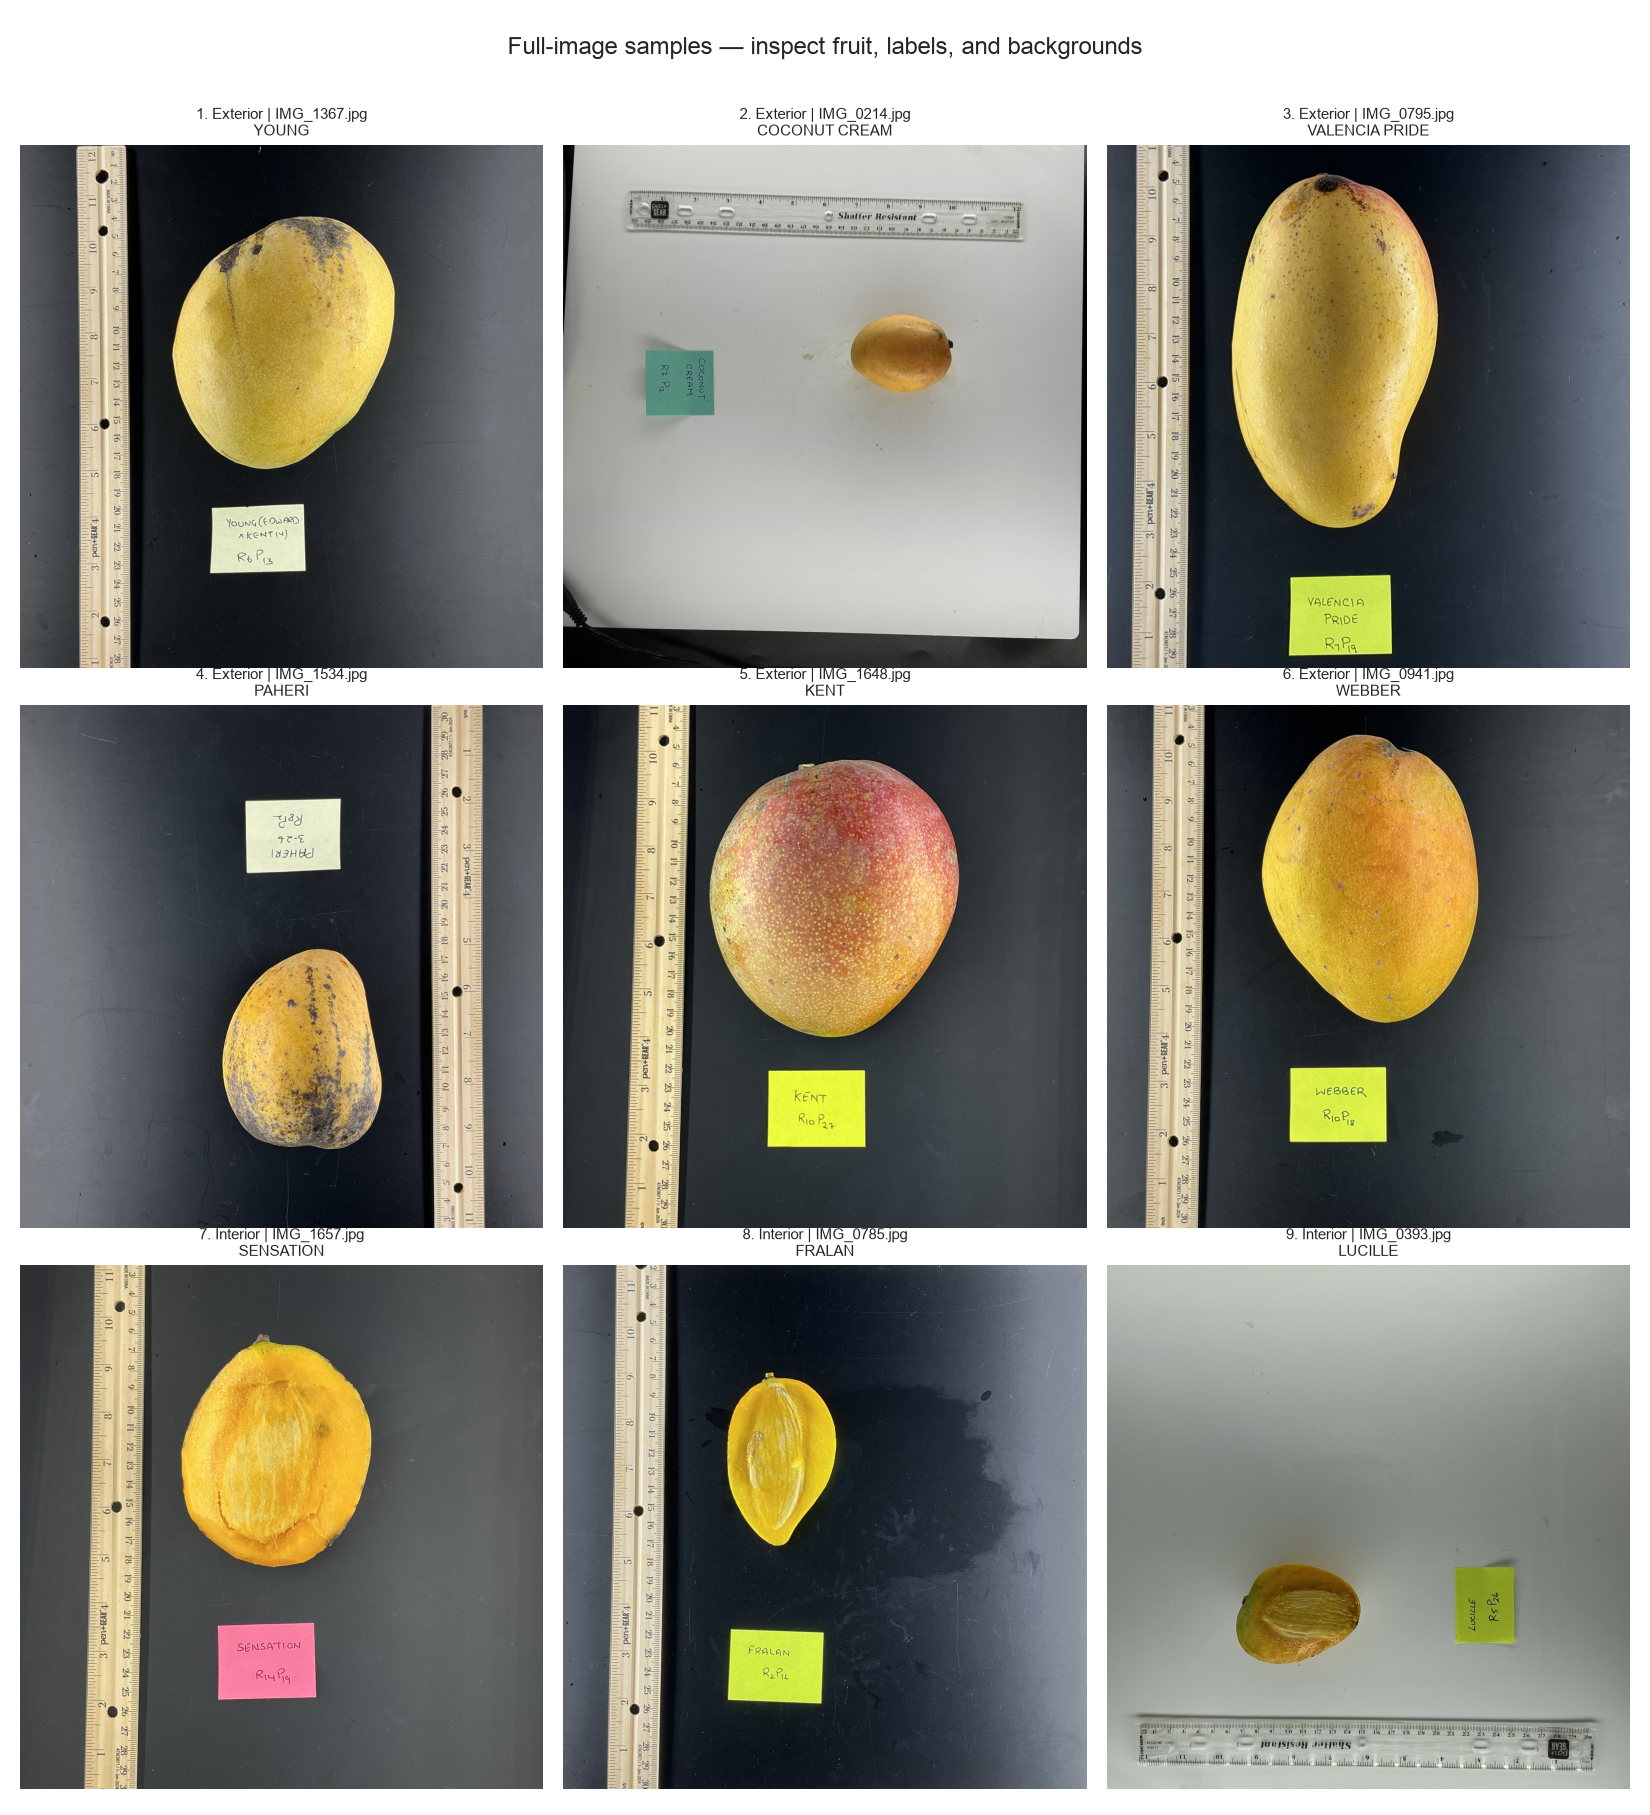

In [ ]:
# Sample six exterior and three interior JPEGs, choosing different varieties within each view to inspect a range of scenes.
# Show the full images so label cards, rulers, surfaces, and other background details remain visible.
# The seed repeats the same sample; change PREVIEW_SEED to inspect another set without modifying any images.

import textwrap

PREVIEW_SEED = SEED
sample_parts = []
for view, count in [("exterior", 6), ("interior", 3)]:
    candidates = df[df["view"].eq(view)].sort_values("image_path")
    selected = (
        candidates.sample(frac=1, random_state=PREVIEW_SEED)
        .drop_duplicates("class_name")
        .head(count)
    )
    sample_parts.append(selected)

sample_images_df = pd.concat(sample_parts, ignore_index=True)
if sample_images_df.empty:
    raise ValueError("No labeled interior or exterior images are available to preview.")

columns = 3
rows = (len(sample_images_df) + columns - 1) // columns
sample_fig, axes = plt.subplots(rows, columns, figsize=(15, 5.5 * rows), squeeze=False)

for index, (ax, row) in enumerate(zip(axes.flat, sample_images_df.itertuples(index=False)), start=1):
    with Image.open(row.image_path) as opened:
        preview = ImageOps.exif_transpose(opened).convert("RGB")
        preview.thumbnail((1000, 1000), Image.Resampling.LANCZOS)
    ax.imshow(preview)
    ax.set_title(
        f"{index}. {row.view.title()} | {Path(row.image_path).name}\n"
        + textwrap.fill(row.class_name, width=38),
        fontsize=10,
    )

for ax in axes.flat:
    ax.axis("off")

sample_fig.suptitle("Full-image samples — inspect fruit, labels, and backgrounds", fontsize=16)
sample_fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()
print(f"Showing {len(sample_images_df)} images selected for variety, not a random estimate of dataset quality.")


In [ ]:
# Define mild training-time changes for both exterior and interior models while keeping RGB color.
# Training gets a fresh random version each time; validation and testing only use consistent resizing and normalization.
# Augmentation does not remove label cards or fix the original framing, and it does not create new independent specimens.

import torch
from torchvision import transforms
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = 224
PADDING_COLOR = (124, 116, 104)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def resize_with_padding(image):
    return ImageOps.pad(
        image.convert("RGB"),
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR,
        color=PADDING_COLOR,
    )


# Keep these separate from normalization so the preview shows natural colors.
train_image_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=15,
        interpolation=InterpolationMode.BILINEAR,
        expand=True,
        fill=PADDING_COLOR,
    ),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.05),
    transforms.Lambda(resize_with_padding),
    # Shrink slightly instead of zooming in and potentially cutting off the fruit.
    transforms.RandomAffine(
        degrees=0,
        scale=(0.90, 1.00),
        interpolation=InterpolationMode.BILINEAR,
        fill=PADDING_COLOR,
    ),
])

eval_image_transform = transforms.Compose([
    transforms.Lambda(resize_with_padding),
])

to_normalized_tensor = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_transform = transforms.Compose([train_image_transform, to_normalized_tensor])
eval_transform = transforms.Compose([eval_image_transform, to_normalized_tensor])


def load_model_image(image_path, *, training=False):
    """Call from a dataset's __getitem__; training=True only for training rows."""
    with Image.open(image_path) as opened:
        image = ImageOps.exif_transpose(opened).convert("RGB")
    transform = train_transform if training else eval_transform
    return transform(image)


print("Training: horizontal flips, rotations up to 15 degrees, mild lighting/color changes, and 90–100% scale.")
print("Validation/test: fixed RGB resizing, padding, and ImageNet normalization only.")
print("Use load_model_image(path, training=True) after splitting original images into training/validation/test.")


In [35]:
# Keep classes with at least 4 original images, separately for each view.
# Show the remaining class and image counts, plus the image count for every retained class.

MIN_IMAGES_PER_CLASS = 4

model_frames = {}
model_class_names = {}
model_class_to_id = {}
model_label_maps = {}
model_class_counts = {}
summary_rows = []

for view in ["exterior", "interior"]:
    view_df = df[df["view"].eq(view)].copy()
    counts_before = view_df["class_name"].value_counts()

    keep_classes = counts_before[
        counts_before >= MIN_IMAGES_PER_CLASS
    ].index

    filtered_df = (
        view_df[view_df["class_name"].isin(keep_classes)]
        .copy()
        .reset_index(drop=True)
    )

    # Assign consecutive class IDs for each separate model
    names = sorted(filtered_df["class_name"].unique())
    class_mapping = {name: index for index, name in enumerate(names)}

    filtered_df["catalog_class_id"] = filtered_df["class_id"]
    filtered_df["class_id"] = (
        filtered_df["class_name"].map(class_mapping).astype("int64")
    )

    model_frames[view] = filtered_df
    model_class_names[view] = names
    model_class_to_id[view] = class_mapping
    model_label_maps[view] = {
        index: name for name, index in class_mapping.items()
    }

    class_counts = filtered_df["class_name"].value_counts()
    model_class_counts[view] = (
        class_counts.rename_axis("Class").to_frame("Image count")
    )

    summary_rows.append({
        "Dataset": view.title(),
        "Classes before": len(counts_before),
        "Images before": len(view_df),
        "Classes remaining": len(class_counts),
        "Images remaining": len(filtered_df),
        "Avg images per class": (
            round(class_counts.mean(), 2) if len(class_counts) else 0
        ),
    })

exterior_df = model_frames["exterior"]
interior_df = model_frames["interior"]

exterior_class_counts = model_class_counts["exterior"]
interior_class_counts = model_class_counts["interior"]

model_summary = pd.DataFrame(summary_rows).set_index("Dataset")
display(model_summary)

# for view, counts in model_class_counts.items():
#     print(f"\n{view.upper()} — IMAGES PER CLASS")
#     with pd.option_context("display.max_rows", None):
#         display(counts)

,Classes before,Images before,Classes remaining,Images remaining,Avg images per class
Dataset,,,,,
Exterior,216,751,78,470,6.03
Interior,210,635,59,325,5.51


## Four transfer-learning experiments

| Name | Class selection | Split rule |
| --- | --- | --- |
| `interior_3plus` | Interior; at least 4 images and 3 code/hash groups per class | Keep groups together |
| `interior_4plus` | Interior; at least 4 images per class | Stratify images; report code overlap |
| `exterior_3plus` | Exterior; at least 4 images and 3 code/hash groups per class | Keep groups together |
| `exterior_4plus` | Exterior; at least 4 images per class | Stratify images; report code overlap |

Every selected class must appear in training, validation, and test. Targets are 60/20/20; counts are approximate because classes and groups are small. Exact duplicate images stay together in every experiment. Codes remain unverified relationship proxies.

Compare ResNet50, VGG16, and EfficientNetB0 **within each experiment**. Different class sets and splitting policies are separate benchmarks. All inputs currently include the full photo, including backgrounds and labels. Train with RGB augmentation and balanced sampling; select dropout and checkpoints using validation only.

The cells below are the current four-experiment workflow. Earlier cells cover catalog exploration. Training and final test evaluation each have an explicit run switch.

Evaluation includes top-1, top-3, top-5, top-10, and top-20 accuracy: the fraction of images whose correct cultivar appears in the first k predictions. Top-1 is ordinary accuracy. All four current experiments have at least 24 classes; if a later experiment has fewer than k classes, use all its classes.


In [36]:
# Load the shared PyTorch helpers and choose training settings for all four experiments.
# Each model uses a frozen pretrained image encoder and a small multiclass classification head.
# We create models one at a time to keep memory use manageable.

import sys
import importlib
import torch
from pathlib import Path

scripts_dir = str(ml_root / "scripts")
if scripts_dir not in sys.path:
    sys.path.insert(0, scripts_dir)
import mango_transfer as transfer
transfer = importlib.reload(transfer)

torch.hub.set_dir(str(ml_root / "runs/.torch-cache"))
DEVICE = transfer.choose_device()
ARCHITECTURES = ["ResNet50", "VGG16", "EfficientNetB0"]
DEFAULT_DROPOUT = 0.35
DROPOUT_RATES = [0.3, 0.4, 0.5, 0.6, 0.7]
EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
BATCH_SIZE = 16
print(f"Device: {DEVICE}; backbones: {', '.join(ARCHITECTURES)}")


Device: mps; backbones: ResNet50, VGG16, EfficientNetB0


In [37]:
# Create four separate labeled datasets, each with its own consecutive class IDs and fixed split membership.
# The 3+ versions keep code-related images together; the 4+ versions use individual-image splits with exact copies kept together.
# Show dataset sizes, actual split sizes, and any related groups crossing splits.

experiments = transfer.prepare_experiments(jpg_manifest, ml_root, seed=SEED)
interior_3plus_df = experiments["interior_3plus"]["frame"]
interior_4plus_df = experiments["interior_4plus"]["frame"]
exterior_3plus_df = experiments["exterior_3plus"]["frame"]
exterior_4plus_df = experiments["exterior_4plus"]["frame"]

experiment_summary, experiment_split_summary, experiment_overlap_summary = transfer.experiment_tables(experiments)
display(experiment_summary)
display(experiment_split_summary)
print("Number of relationships crossing splits (code overlap is permitted only in 4+):")
display(experiment_overlap_summary)

experiment_splits = {key: experiment["splits"] for key, experiment in experiments.items()}
split_plan_path = transfer.save_split_plan(experiments, ml_root / "runs/four-model-transfer", jpg_manifest)
print(f"Saved exact split membership: {split_plan_path}")


,Classes,Images,Avg images/class,Split policy
Experiment,,,,
interior_3plus,24,163,6.79,4+ images and 3+ code/hash groups; groups kept...
interior_4plus,59,325,5.51,"4+ images; image-stratified, exact copies kept..."
exterior_3plus,24,191,7.96,4+ images and 3+ code/hash groups; groups kept...
exterior_4plus,78,470,6.03,"4+ images; image-stratified, exact copies kept..."


Images  Classes  Percent
Experiment     Split                               
interior_3plus train           87       24     53.4
               validation      34       24     20.9
               test            42       24     25.8
interior_4plus train          185       59     56.9
               validation      70       59     21.5
               test            70       59     21.5
exterior_3plus train          105       24     55.0
               validation      41       24     21.5
               test            45       24     23.6
exterior_4plus train          268       78     57.0
               validation     101       78     21.5
               test           101       78     21.5

Number of relationships crossing splits (code overlap is permitted only in 4+):


Relationship,annotation_code,duplicate_group,split_group
Experiment,,,
exterior_3plus,0,0,0
exterior_4plus,102,0,102
interior_3plus,0,0,0
interior_4plus,69,0,69


Saved exact split membership: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/runs/four-model-transfer/split-plan-20261011T215629098570Z/splits.json


In [41]:
# Build training, validation, and test loaders for each of the four datasets.
# Training samples classes with equal expected probability and applies fresh random augmentation each time an image is loaded.
# Validation and test preserve their actual class counts and use only fixed preprocessing.

experiment_loaders = {
    key: {split: transfer.make_loader(experiment, split, batch_size=BATCH_SIZE, seed=SEED)
          for split in transfer.SPLITS}
    for key, experiment in experiments.items()
}
display(pd.DataFrame([
    {"Experiment": key, "Train images": len(loaders["train"].dataset),
     "Validation images": len(loaders["validation"].dataset),
     "Test images": len(loaders["test"].dataset),
     "Train batches/epoch": len(loaders["train"])}
    for key, loaders in experiment_loaders.items()
]).set_index("Experiment"))
# Example: experiment_loaders["interior_3plus"]["train"]


,Train images,Validation images,Test images,Train batches/epoch
Experiment,,,,
interior_3plus,87,34,42,6
interior_4plus,185,70,70,12
exterior_3plus,105,41,45,7
exterior_4plus,268,101,101,17


In [42]:
# Define the 12 model configurations: three pretrained architectures for each of the four datasets.
# Replace the original classifier with a dropout/128-unit/multiclass head; only this new head learns initially.
# The output is one score per mango variety, trained with cross-entropy rather than binary loss.

def create_transfer_model(experiment_name, architecture, dropout=DEFAULT_DROPOUT):
    return transfer.create_model(
        architecture, len(experiments[experiment_name]["class_names"]), dropout=dropout,
    ).to(DEVICE)

model_specs = pd.DataFrame([
    {"Experiment": key, "Architecture": architecture,
     "Output classes": len(experiment["class_names"]),
     "Head": "Dropout → Linear(128) → ReLU → Dropout → Linear(classes)",
     "Backbone": "Frozen ImageNet weights"}
    for key, experiment in experiments.items() for architecture in ARCHITECTURES
])
display(model_specs)
# Example: model = create_transfer_model("interior_3plus", "ResNet50")
# Training below constructs each model automatically and saves its selected head.


,Experiment,Architecture,Output classes,Head,Backbone
0,interior_3plus,ResNet50,24,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
1,interior_3plus,VGG16,24,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
2,interior_3plus,EfficientNetB0,24,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
3,interior_4plus,ResNet50,59,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
4,interior_4plus,VGG16,59,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
5,interior_4plus,EfficientNetB0,59,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
6,exterior_3plus,ResNet50,24,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
7,exterior_3plus,VGG16,24,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
8,exterior_3plus,EfficientNetB0,24,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights
9,exterior_4plus,ResNet50,78,Dropout → Linear(128) → ReLU → Dropout → Linea...,Frozen ImageNet weights


In [48]:
# Train all 12 configurations when RUN_TRAINING is True, saving each run in its own directory.
# Optionally compare the five dropout rates using the full training/validation splits and select the lowest validation loss.
# Early stopping restores the best validation checkpoint; this cell never evaluates the test set.

RUN_TRAINING = True
RUN_DROPOUT_SWEEP = False

if RUN_TRAINING:
    training_results = transfer.run_training(
        experiments, jpg_manifest, ml_root / "runs/four-model-transfer",
        architectures=ARCHITECTURES,
        dropout_rates=DROPOUT_RATES if RUN_DROPOUT_SWEEP else [DEFAULT_DROPOUT],
        epochs=EPOCHS, patience=PATIENCE, learning_rate=LEARNING_RATE,
        batch_size=BATCH_SIZE, device=DEVICE, seed=SEED,
    )
    validation_results = pd.DataFrame([
        {"Experiment": key, "Architecture": architecture,
         "Selected dropout": result["dropout"], "Best epoch": result["best_epoch"],
         **result["validation"], "Run directory": result["run_dir"]}
        for (key, architecture), result in training_results.items()
    ])
    display(validation_results)
else:
    print("Ready to train: set RUN_TRAINING = True. Enable RUN_DROPOUT_SWEEP for 60 trials instead of 12.")



interior_3plus / ResNet50 / dropout=0.35
Epoch 1: train loss 3.283; validation loss 3.317; top-1 2.9%; top-3 8.8%; top-5 20.6%; top-10 29.4%; top-20 82.4%; macro F1 0.003
Epoch 2: train loss 3.269; validation loss 3.306; top-1 2.9%; top-3 14.7%; top-5 20.6%; top-10 29.4%; top-20 79.4%; macro F1 0.003
Epoch 3: train loss 3.053; validation loss 3.337; top-1 2.9%; top-3 8.8%; top-5 14.7%; top-10 32.4%; top-20 79.4%; macro F1 0.006
Epoch 4: train loss 3.063; validation loss 3.307; top-1 2.9%; top-3 11.8%; top-5 23.5%; top-10 35.3%; top-20 79.4%; macro F1 0.042
Epoch 5: train loss 3.044; validation loss 3.286; top-1 5.9%; top-3 8.8%; top-5 23.5%; top-10 44.1%; top-20 76.5%; macro F1 0.018
Epoch 6: train loss 2.903; validation loss 3.207; top-1 2.9%; top-3 8.8%; top-5 26.5%; top-10 47.1%; top-20 82.4%; macro F1 0.003
Epoch 7: train loss 2.785; validation loss 3.206; top-1 2.9%; top-3 8.8%; top-5 29.4%; top-10 55.9%; top-20 88.2%; macro F1 0.003
Epoch 8: train loss 2.686; validation loss 3.2

,Experiment,Architecture,Selected dropout,Best epoch,accuracy,macro_precision,macro_recall,macro_f1,top1_accuracy,top3_accuracy,top5_accuracy,top10_accuracy,top20_accuracy,output_classes,classes_evaluated,images,loss,Run directory
0,interior_3plus,ResNet50,0.35,7,0.029412,0.001603,0.041667,0.003086,0.029412,0.088235,0.294118,0.558824,0.882353,24,24,34,3.205643,/Users/danielgeorge/Desktop/coding/cis4914-sen...
1,interior_3plus,VGG16,0.35,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.117647,0.235294,0.411765,0.852941,24,24,34,3.175529,/Users/danielgeorge/Desktop/coding/cis4914-sen...
2,interior_3plus,EfficientNetB0,0.35,2,0.147059,0.061508,0.097222,0.052083,0.147059,0.205882,0.382353,0.617647,0.882353,24,24,34,3.124412,/Users/danielgeorge/Desktop/coding/cis4914-sen...
3,interior_4plus,ResNet50,0.35,10,0.028571,0.001398,0.033898,0.002684,0.028571,0.114286,0.157143,0.314286,0.571429,59,59,70,3.910670,/Users/danielgeorge/Desktop/coding/cis4914-sen...
4,interior_4plus,VGG16,0.35,9,0.028571,0.001750,0.033898,0.003290,0.028571,0.114286,0.185714,0.300000,0.542857,59,59,70,3.943380,/Users/danielgeorge/Desktop/coding/cis4914-sen...
5,interior_4plus,EfficientNetB0,0.35,10,0.057143,0.038136,0.067797,0.046328,0.057143,0.214286,0.300000,0.500000,0.714286,59,59,70,3.589922,/Users/danielgeorge/Desktop/coding/cis4914-sen...
6,exterior_3plus,ResNet50,0.35,5,0.048780,0.016369,0.083333,0.027083,0.048780,0.097561,0.243902,0.463415,0.829268,24,24,41,3.296356,/Users/danielgeorge/Desktop/coding/cis4914-sen...
7,exterior_3plus,VGG16,0.35,1,0.048780,0.002381,0.041667,0.004505,0.048780,0.146341,0.243902,0.463415,0.780488,24,24,41,3.187152,/Users/danielgeorge/Desktop/coding/cis4914-sen...
8,exterior_3plus,EfficientNetB0,0.35,3,0.048780,0.016865,0.083333,0.026389,0.048780,0.219512,0.365854,0.536585,0.926829,24,24,41,3.154615,/Users/danielgeorge/Desktop/coding/cis4914-sen...
9,exterior_4plus,ResNet50,0.35,10,0.029703,0.014777,0.038462,0.016434,0.029703,0.158416,0.217822,0.336634,0.584158,78,78,101,3.981665,/Users/danielgeorge/Desktop/coding/cis4914-sen...


## Top-k cultivar accuracy

Run the next cell to show validation accuracy for each dataset and model. For example, top-20 accuracy of 80% means the correct cultivar appeared in the first 20 predictions for 80% of validation images. This uses completed saved models and does not start training.


In [49]:
# Show how often the correct cultivar is in the top 1, 3, 5, 10, or 20 predictions on validation images.
# Reuse completed training results, or load completed checkpoints from disk; older runs get the missing scores without retraining.
# Each row identifies its dataset and model, and models that have not finished training are marked as pending.

import json

TOP_K_VALUES = (1, 3, 5, 10, 20)

def calculate_topk_accuracy(model, loader, device):
    model.eval()
    hits = {k: 0 for k in TOP_K_VALUES}
    image_count = 0
    with torch.inference_mode():
        for images, labels in loader:
            scores = model(images.to(device))
            ranked_classes = scores.argsort(dim=1, descending=True, stable=True)
            correct_at_rank = ranked_classes.eq(labels.to(device)[:, None])
            class_count = scores.shape[1]
            for k in TOP_K_VALUES:
                hits[k] += correct_at_rank[:, :min(k, class_count)].any(dim=1).sum().item()
            image_count += len(labels)
    if image_count == 0:
        raise ValueError("This validation split contains no images.")
    return {"images": image_count, "output_classes": class_count,
            **{f"top{k}_accuracy": hits[k] / image_count for k in TOP_K_VALUES}}


# A completed training session takes priority; otherwise use the latest completed checkpoint per configuration.
completed_runs = {}
for metadata_path in sorted((ml_root / "runs/four-model-transfer").glob("*/experiment.json")):
    if (metadata_path.parent / "head.pt").exists():
        saved = json.loads(metadata_path.read_text())
        completed_runs[(saved["experiment"], saved["architecture"])] = {"run_dir": str(metadata_path.parent)}
completed_runs.update(globals().get("training_results", {}))

topk_rows = []
for experiment_name in experiments:
    for architecture in ARCHITECTURES:
        row = {"Experiment": experiment_name, "Architecture": architecture, "Split": "Validation"}
        result = completed_runs.get((experiment_name, architecture))
        if result is None:
            row.update({"Status": "Awaiting training", "Cultivars": len(experiments[experiment_name]["class_names"]),
                        "Images": None, **{f"Top-{k} accuracy (%)": None for k in TOP_K_VALUES}})
            topk_rows.append(row)
            continue

        run_dir = Path(result["run_dir"])
        saved = json.loads((run_dir / "experiment.json").read_text())
        metrics = result.get("validation", saved["validation"])
        if not all(f"top{k}_accuracy" in metrics for k in TOP_K_VALUES):
            print(f"Calculating validation top-k: {experiment_name} / {architecture}", flush=True)
            validation_frame = pd.DataFrame([item for item in saved["split_rows"] if item["split"] == "validation"])
            validation_frame["image_path"] = validation_frame.raw_path.map(lambda p: str(ml_root / p))
            loader = transfer.make_loader({"splits": {"validation": validation_frame}}, "validation", BATCH_SIZE)
            model, class_names = transfer.load_run(run_dir, device=DEVICE)
            try:
                if class_names != saved["class_names"]:
                    raise ValueError("Checkpoint class names do not match its saved validation labels.")
                metrics = calculate_topk_accuracy(model, loader, DEVICE)
            finally:
                model.cpu()
                del model

        row.update({"Status": "Completed", "Cultivars": len(saved["class_names"]), "Images": metrics["images"],
                    **{f"Top-{k} accuracy (%)": round(100 * metrics[f"top{k}_accuracy"], 2) for k in TOP_K_VALUES}})
        topk_rows.append(row)

topk_results = pd.DataFrame(topk_rows)
print("Validation accuracy: correct cultivar anywhere in the first k predictions.")
display(topk_results)


Validation accuracy: correct cultivar anywhere in the first k predictions.


,Experiment,Architecture,Split,Status,Cultivars,Images,Top-1 accuracy (%),Top-3 accuracy (%),Top-5 accuracy (%),Top-10 accuracy (%),Top-20 accuracy (%)
0,interior_3plus,ResNet50,Validation,Completed,24,34,2.94,8.82,29.41,55.88,88.24
1,interior_3plus,VGG16,Validation,Completed,24,34,0.00,11.76,23.53,41.18,85.29
2,interior_3plus,EfficientNetB0,Validation,Completed,24,34,14.71,20.59,38.24,61.76,88.24
3,interior_4plus,ResNet50,Validation,Completed,59,70,2.86,11.43,15.71,31.43,57.14
4,interior_4plus,VGG16,Validation,Completed,59,70,2.86,11.43,18.57,30.00,54.29
5,interior_4plus,EfficientNetB0,Validation,Completed,59,70,5.71,21.43,30.00,50.00,71.43
6,exterior_3plus,ResNet50,Validation,Completed,24,41,4.88,9.76,24.39,46.34,82.93
7,exterior_3plus,VGG16,Validation,Completed,24,41,4.88,14.63,24.39,46.34,78.05
8,exterior_3plus,EfficientNetB0,Validation,Completed,24,41,4.88,21.95,36.59,53.66,92.68
9,exterior_4plus,ResNet50,Validation,Completed,78,101,2.97,15.84,21.78,33.66,58.42


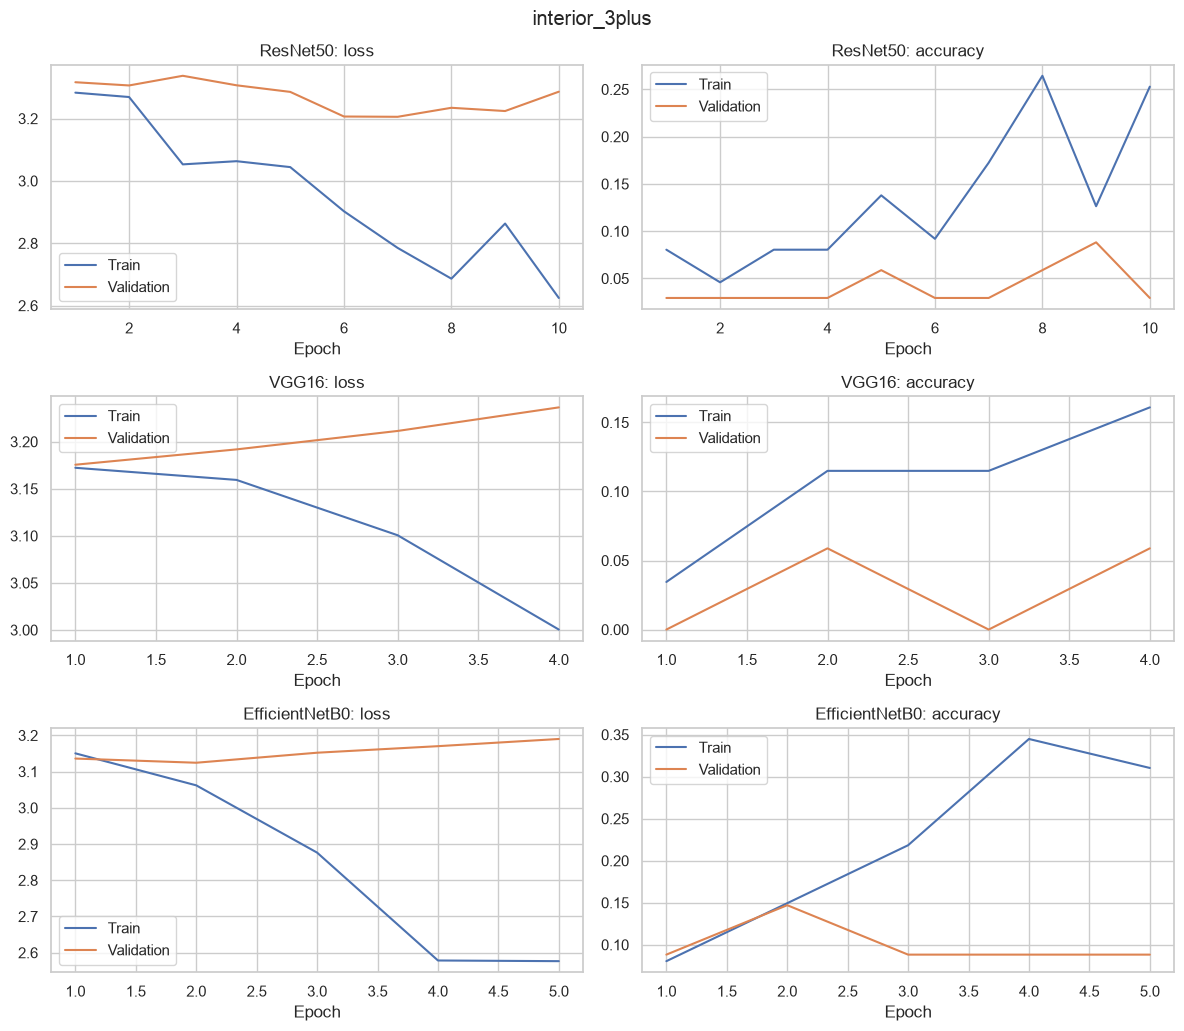

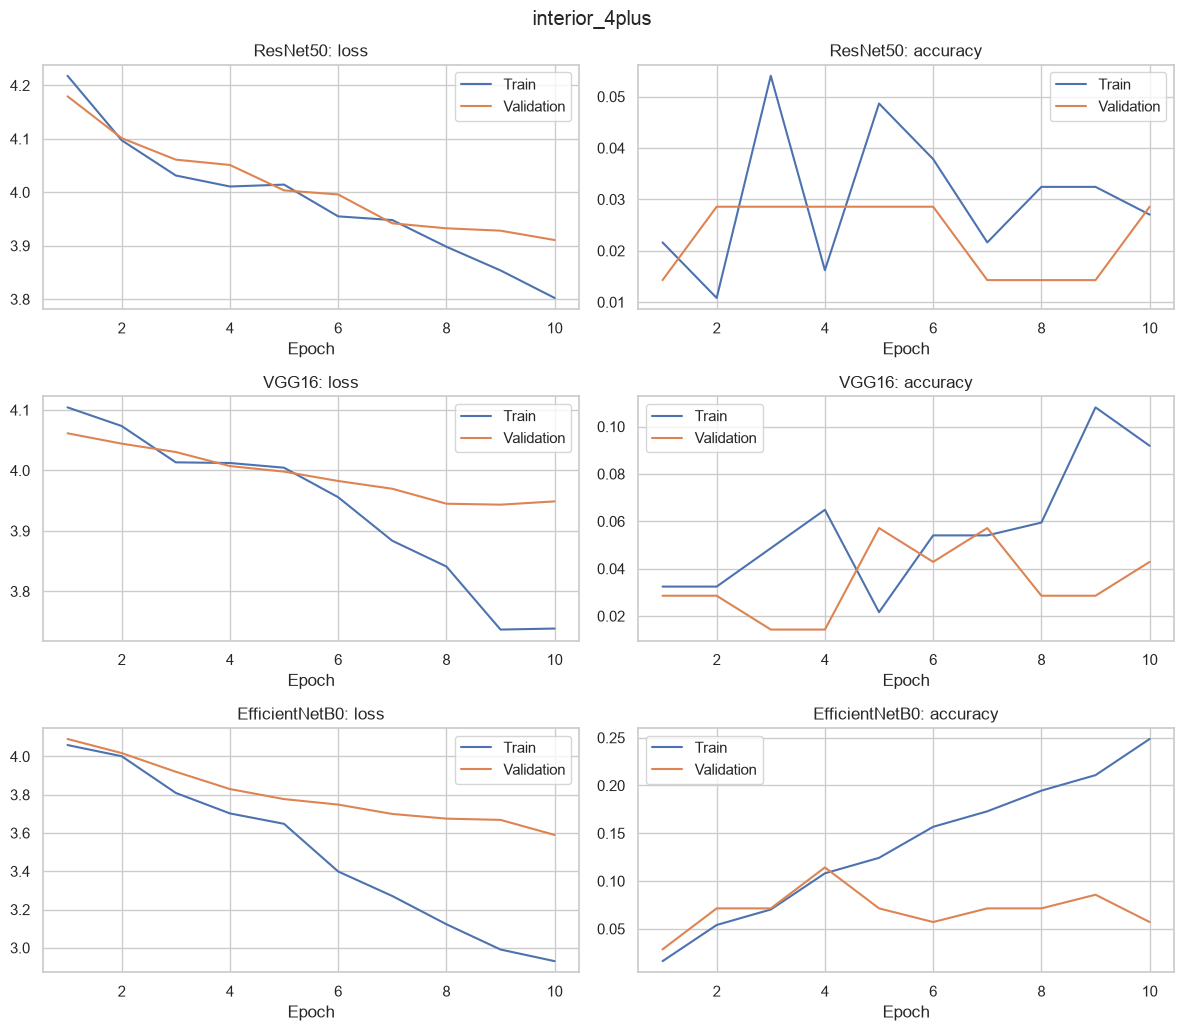

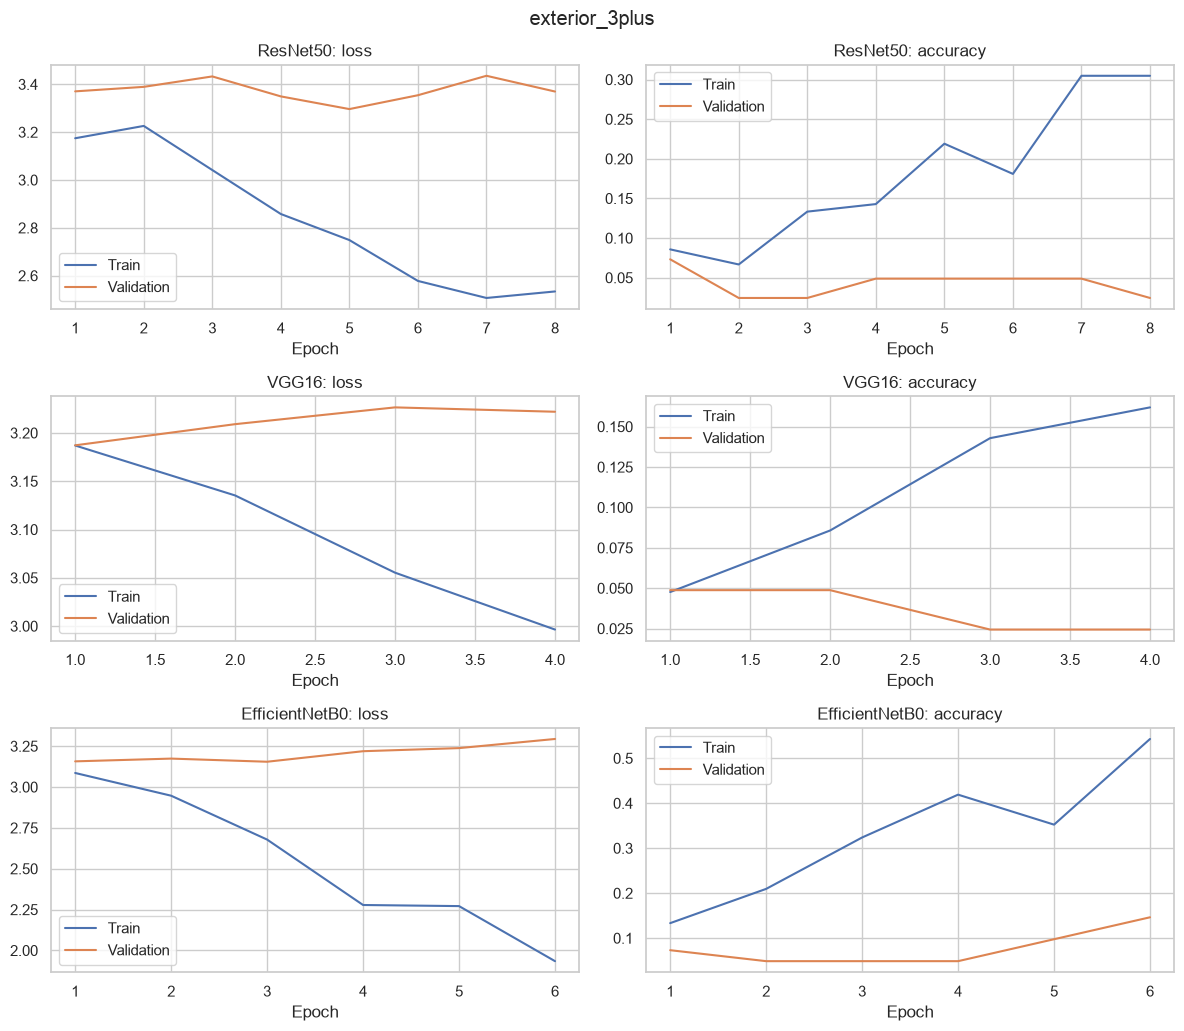

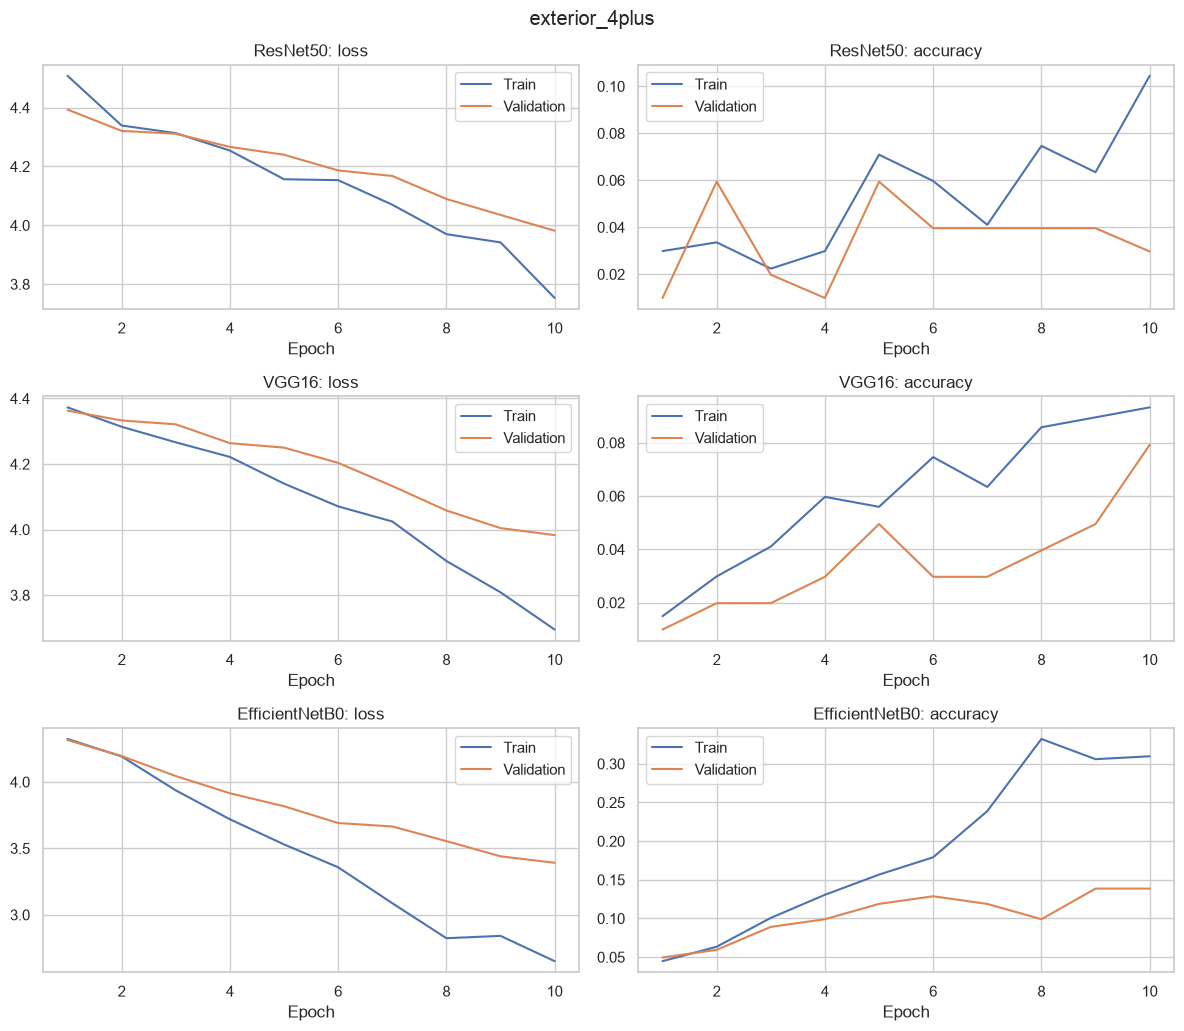

In [50]:
# Plot training and validation loss/accuracy for each completed architecture within each experiment.
# These curves show whether training improves validation performance or starts overfitting.
# Training accuracy is measured on sampled augmented images; validation accuracy uses fixed original inputs.

if "training_results" in globals() and training_results:
    for experiment_name in experiments:
        runs = [(architecture, result) for (key, architecture), result in training_results.items()
                if key == experiment_name]
        fig, axes = plt.subplots(len(runs), 2, figsize=(12, 3.5 * len(runs)), squeeze=False)
        for row, (architecture, result) in enumerate(runs):
            history = pd.DataFrame(result["history"])
            for column, metric in enumerate(["loss", "accuracy"]):
                ax = axes[row, column]
                ax.plot(history["epoch"], history[f"train_{metric}"], label="Train")
                ax.plot(history["epoch"], history[f"val_{metric}"], label="Validation")
                ax.set_title(f"{architecture}: {metric}")
                ax.set_xlabel("Epoch")
                ax.legend()
        fig.suptitle(experiment_name)
        fig.tight_layout()
        plt.show()
else:
    print("Train the models first to display learning curves.")


In [52]:
# Evaluate the selected models on the final test set after settling model settings.
# The top-k validation table is in the dedicated cell directly after training.
# Keep these test scores separate from the validation results used during development.

RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    if "training_results" not in globals() or not training_results:
        raise ValueError("Run training before final test evaluation.")
    test_results, test_details = transfer.evaluate_saved_runs(
        training_results, experiments, batch_size=BATCH_SIZE, device=DEVICE,
    )
    display(test_results.round(4))
else:
    print("For top-k validation accuracy, run the Top-k cultivar accuracy cell immediately after training.")


For top-k validation accuracy, run the Top-k cultivar accuracy cell immediately after training.


In [54]:
# List the top 20 predicted cultivars for a JPEG, ordered from most to least likely; change top_k to show 5, 10, or another number.
# If you provide the known cultivar, the table marks it and the printed result tells you its rank, even if it falls outside the displayed list.
# Scores are the model's softmax outputs, not accuracy or calibrated confidence.

transfer = importlib.reload(transfer)

def predict_mango(image_path, experiment_name="interior_3plus", architecture="ResNet50",
                  top_k=20, actual_class=None):
    if "training_results" not in globals() or not training_results:
        raise ValueError("Train a model first to create a saved checkpoint.")
    selected_run = training_results[(experiment_name, architecture)]["run_dir"]
    predictions = transfer.predict_image(
        selected_run, image_path, top_k=top_k, device=DEVICE, actual_class=actual_class,
    )
    if actual_class is not None:
        rank = predictions.attrs["actual_rank"]
        total = predictions.attrs["output_classes"]
        found = "yes" if rank <= len(predictions) else "no"
        print(f"Correct cultivar: {predictions.attrs['actual_class']}; rank {rank} of {total}; "
              f"in top {len(predictions)}: {found}")
    return predictions

# Example after training (uncomment to inspect one labeled test image):
example = experiments["exterior_3plus"]["splits"]["test"].iloc[0]

display(predict_mango(example.image_path, "exterior_3plus", "ResNet50",
                      top_k=20, actual_class=example.class_name))


Correct cultivar: EDWARD; rank 2 of 24; in top 20: yes


,rank,class_name,score,is_correct_cultivar
0,1,CAMBODIANA,0.125134,False
1,2,EDWARD,0.096342,True
2,3,COGSHALL,0.084843,False
3,4,MESK,0.070585,False
4,5,ROSIGOLD,0.060136,False
5,6,RUBY,0.054600,False
6,7,SAIGON,0.048881,False
7,8,CARABAO,0.040604,False
8,9,DUNCAN,0.038602,False
9,10,SENSATION,0.038249,False
